# **AI METHODS I**
## Hackathon · Notebook 1: Autoencoders

Welcome to the hackathon week! By Friday every team has a **live app**: a web page behind a password that sends an input to **your own model**, running online as a small web service, and stores the answer in a database. The model is an **autoencoder**. This notebook is Monday's hands-on part: what an autoencoder is, how to train one, and the five things you can do with it.

The hackathon has two notebooks:

| Notebook | Topic | When |
|---|---|---|
| **1 · this one** | Autoencoders: train them, compare setups, use them for compression, similarity search, denoising, anomaly detection and generation | Monday |
| 2 | Bring the model online: model server (Gradio on Render), Cloudflare app, password, database, diagrams | Tuesday to Friday |

### What is an autoencoder?

An autoencoder is a neural network trained to **copy its input to its output**, through a narrow middle layer:

```
   input (784 pixels)                                         output (784 pixels)
  ┌───────────────┐    ┌─────────┐    ┌───────┐    ┌─────────┐    ┌───────────────┐
  │ ░░▓▓▓▓▓▓▓▓░░  │ ─▶ │ ENCODER │ ─▶ │ code  │ ─▶ │ DECODER │ ─▶ │ ░░▓▓▓▓▓▓▓░░░  │
  │ ░▓▓▓▓▓▓▓▓▓▓░  │    │ squeeze │    │ 8–32  │    │ rebuild │    │ ░▓▓▓▓▓▓▓▓▓▓░  │
  └───────────────┘    └─────────┘    │numbers│    └─────────┘    └───────────────┘
                                      └───────┘
                                    "latent space"
          loss = how different the output is from the input (reconstruction error)
```

Copying sounds useless. The trick is the **bottleneck**: the network cannot pass all 784 pixels through 8 numbers, so it has to learn **what matters** in the data. No labels are needed: the input is its own target. This is **unsupervised** learning, as on Day 3, but with a neural network.

### The five uses (Monday's input)

| Use | Idea | Built-environment example |
|---|---|---|
| **Compression** | The code is a short summary of the input | Store thousands of sensor days as 8 numbers each |
| **Similarity search** | Similar inputs get similar codes | "Find the floor plans that look like this one" |
| **Denoising** | Train with noisy input and clean target | Clean a scanned drawing or a noisy recording |
| **Anomaly detection** | Trained on normal data, it rebuilds anomalies badly | Flag a faulty HVAC day, a weld defect, an unusual machine sound |
| **Generative design** | Decode new codes (a **VAE**) | Generate and blend structural forms or layouts |

### Learning goals
By the end of this notebook you will be able to:
1. Build and train a **dense** and a **convolutional** autoencoder in PyTorch.
2. **Compare setups** (architecture, latent size) with a fair table of results.
3. Use the latent space for **similarity search** and look at it with UMAP.
4. Train a **denoising** autoencoder and an **anomaly detector** with a threshold.
5. Generate new samples with a **variational autoencoder** (VAE).
6. **Save** a model, its settings and its threshold, ready for notebook 2.

### Table of contents
0. Setup
1. The data
2. A dense autoencoder
3. A convolutional autoencoder
4. Compression: how small can the code be?
5. The latent space and similarity search
6. Denoising
7. Anomaly detection
8. Generative design with a VAE
9. Saving the model for the model server
10. Your turn: your team's dataset
11. Conclusions and next steps

# 0. Setup

💡 **Tip – Google Colab:** PyTorch, torchvision, scikit-learn and matplotlib are already installed in Colab; `umap-learn` and the ONNX packages (section 9) are missing. On your own computer everything is in the course `requirements.txt`. All models here are small: the notebook runs on a laptop **CPU** in a few minutes, faster with a GPU.

In [55]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install torch torchvision scikit-learn matplotlib umap-learn onnx onnxscript onnxruntime

In [56]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets
from sklearn.metrics import precision_score, recall_score, roc_auc_score
import umap

In [57]:
# --- Folders ------------------------------------------------------------------
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print(f"PyTorch {torch.__version__}, using device: {DEVICE}")


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

PyTorch 2.14.1+cu126, using device: cuda


# 1. The data

### Why a dataset about clothes?
This notebook teaches the **mechanics**, so it uses a small, clean, well-known dataset: **Fashion-MNIST**. Every team then applies the same steps to its own construction dataset from [`DATASETS.md`](DATASETS.md). Using a neutral example means none of the 24 hackathon datasets is "taken" by the class demo.

### Dataset card
| | |
|---|---|
| **Name** | Fashion-MNIST (Zalando Research) |
| **Source** | [github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist), downloaded with `torchvision` |
| **Content** | 70,000 greyscale images of 28 × 28 px (60,000 train, 10,000 test), 10 classes of clothing |
| **Licence** | MIT |
| **We use** | 20,000 training images (to keep CPU training short), 5,000 for validation, the 10,000 test images |

💡 **Tip:** an autoencoder does not need the labels. We only keep them to **colour plots** and to **check** the anomaly detector.

In [58]:
train_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_set = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
CLASS_NAMES = train_full.classes

# Pixels 0–255 -> floats 0–1, shape (N, 1, 28, 28): (images, channels, height, width)
X_all = train_full.data.float().div(255).unsqueeze(1)
y_all = train_full.targets
X_test = test_set.data.float().div(255).unsqueeze(1)
y_test = test_set.targets

# A random 20,000 / 5,000 train / validation split
order = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(RANDOM_STATE))
train_idx, val_idx = order[:20_000], order[20_000:25_000]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

print("train", tuple(X_train.shape), "| validation", tuple(X_val.shape), "| test", tuple(X_test.shape))
print("classes:", CLASS_NAMES)

train (20000, 1, 28, 28) | validation (5000, 1, 28, 28) | test (10000, 1, 28, 28)
classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


Figure saved to figures/nb1_01_samples.png


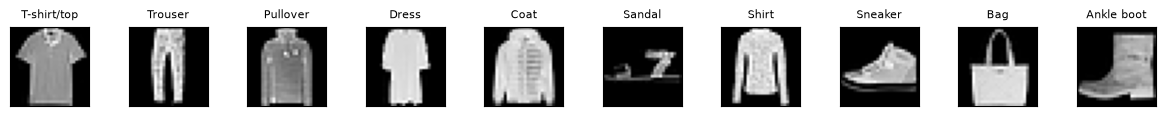

In [59]:
def show_images(rows, titles=None, row_labels=None, size=1.2):
    # rows: a list of image batches (N, 1, H, W); one row of the figure per batch
    n_rows, n_cols = len(rows), len(rows[0])
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows), squeeze=False)
    for r, batch in enumerate(rows):
        for c in range(n_cols):
            ax = axes[r, c]
            ax.imshow(batch[c].squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
            ax.set_xticks([]); ax.set_yticks([])
            if titles is not None and r == 0:
                ax.set_title(titles[c], fontsize=8)
        if row_labels is not None:
            axes[r, 0].set_ylabel(row_labels[r], fontsize=9)
    plt.tight_layout()


first_of_each = [int((y_train == k).nonzero()[0]) for k in range(10)]
show_images([X_train[first_of_each]], titles=CLASS_NAMES)
save_fig("nb1_01_samples")
plt.show()

# 2. A dense autoencoder

The simplest autoencoder is two small MLPs (Day 4, notebook 1) back to back:
- the **encoder** flattens the 28 × 28 image into 784 numbers and squeezes them to a **code** of `latent_dim` numbers;
- the **decoder** expands the code back to 784 numbers. A **sigmoid** at the end keeps the pixels between 0 and 1.

The loss is the **mean squared error** (MSE) between the output and the input: the **reconstruction error**.

In [60]:
class DenseAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),                     # (N, 1, 28, 28) -> (N, 784)
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, latent_dim),       # the code
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),     # back to an image
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

We write the training loop **once** and reuse it for every model in this notebook. It is the Day 4 loop with one change: the **target is the input itself** (or, for the denoising model, the clean version of the input).

In [61]:
def train_autoencoder(model, X_train, X_val, epochs=8, lr=1e-3, batch_size=256, noise=0.0, loss_fn=None, verbose=True):
    # Train an autoencoder to rebuild its input. noise > 0 trains a denoising autoencoder.
    torch.manual_seed(RANDOM_STATE)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = loss_fn or (lambda output, target, model: nn.functional.mse_loss(output, target))
    loader = DataLoader(TensorDataset(X_train), batch_size=batch_size, shuffle=True)
    history = []
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (clean,) in loader:
            clean = clean.to(DEVICE)
            noisy = (clean + noise * torch.randn_like(clean)).clamp(0, 1) if noise > 0 else clean
            output = model(noisy)
            loss = loss_fn(output, clean, model)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(clean)
        val_loss = reconstruction_error(model, X_val).mean().item()
        history.append({"epoch": epoch, "train_loss": total / len(X_train), "val_mse": val_loss})
        if verbose:
            print(f"epoch {epoch:2d}  train loss {total / len(X_train):.4f}  validation MSE {val_loss:.4f}")
    print(f"trained in {time.time() - start:.0f} s")
    return model, pd.DataFrame(history)


@torch.no_grad()
def reconstruct(model, X, batch_size=1000):
    model.eval()
    parts = [model(X[i:i + batch_size].to(DEVICE)) for i in range(0, len(X), batch_size)]
    out = torch.cat(parts).cpu()
    return out[0] if isinstance(out, tuple) else out


@torch.no_grad()
def reconstruction_error(model, X, batch_size=1000):
    # One number per image: the mean squared difference between input and output
    model.eval()
    errors = []
    for i in range(0, len(X), batch_size):
        batch = X[i:i + batch_size].to(DEVICE)
        output = model(batch)
        output = output[0] if isinstance(output, tuple) else output
        errors.append(((output - batch) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors)


def n_params(model):
    return sum(p.numel() for p in model.parameters())

In [62]:
dense_ae, dense_hist = train_autoencoder(DenseAE(latent_dim=16), X_train, X_val)
print(f"{n_params(dense_ae):,} parameters")

epoch  1  train loss 0.0685  validation MSE 0.0367
epoch  2  train loss 0.0296  validation MSE 0.0254
epoch  3  train loss 0.0232  validation MSE 0.0215
epoch  4  train loss 0.0204  validation MSE 0.0193
epoch  5  train loss 0.0187  validation MSE 0.0189
epoch  6  train loss 0.0177  validation MSE 0.0172
epoch  7  train loss 0.0168  validation MSE 0.0165
epoch  8  train loss 0.0162  validation MSE 0.0160
trained in 2 s
410,912 parameters


Figure saved to figures/nb1_02_dense_curve.png


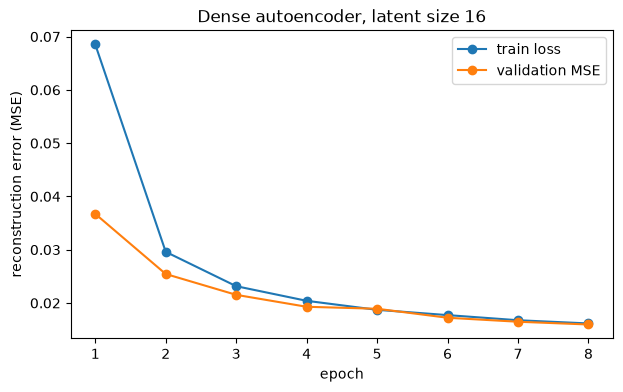

Figure saved to figures/nb1_03_dense_reconstructions.png


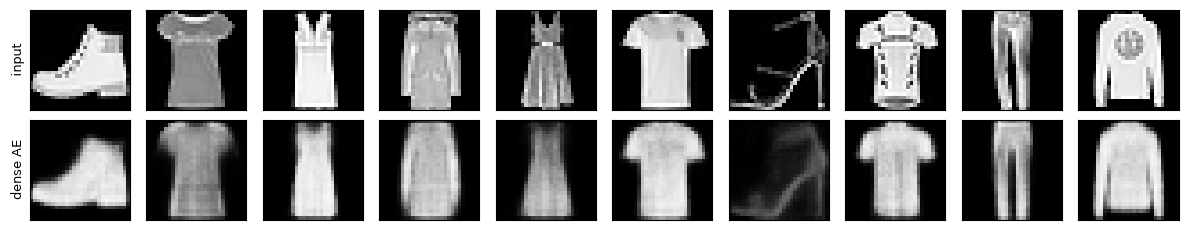

In [63]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dense_hist["epoch"], dense_hist["train_loss"], marker="o", label="train loss")
ax.plot(dense_hist["epoch"], dense_hist["val_mse"], marker="o", label="validation MSE")
ax.set_xlabel("epoch"); ax.set_ylabel("reconstruction error (MSE)")
ax.set_title("Dense autoencoder, latent size 16"); ax.legend()
save_fig("nb1_02_dense_curve")
plt.show()

sample = X_val[:10]
show_images([sample, reconstruct(dense_ae, sample)], row_labels=["input", "dense AE"])
save_fig("nb1_03_dense_reconstructions")
plt.show()

- **It learns fast:** the validation error drops from 0.037 after one epoch to **0.016** after eight, and it is still falling slowly: more epochs would help a little.
- **No overfitting:** the training and validation curves stay together. An autoencoder overfits less easily than a classifier, because every pixel of every image is a training target.
- **What is lost:** the reconstructions keep the **shape** and the overall brightness of each garment, but the **details** (prints, logos, stripes, the straps of the sandal) become blur. 16 numbers are not enough to store them, so the network keeps what is common to many images and drops what is rare. That choice is exactly what makes the code useful.

# 3. A convolutional autoencoder

A dense layer treats every pixel as unrelated to its neighbours. A **convolutional** autoencoder uses the filters of Day 4 instead:
- the encoder **halves** the image twice with strided convolutions (28 → 14 → 7), then a linear layer makes the code;
- the decoder does the opposite with **transposed convolutions** (7 → 14 → 28), which "un-shrink" an image.

```
 1×28×28 ─conv─▶ 16×14×14 ─conv─▶ 32×7×7 ─linear─▶ code ─linear─▶ 32×7×7 ─convT─▶ 16×14×14 ─convT─▶ 1×28×28
```

In [64]:
class ConvAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),    # 28 -> 14
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),   # 14 -> 7
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32 * 7 * 7), nn.ReLU(),
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1), nn.Sigmoid(), # 14 -> 28
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

epoch  1  train loss 0.1104  validation MSE 0.0684
epoch  2  train loss 0.0509  validation MSE 0.0356
epoch  3  train loss 0.0304  validation MSE 0.0268
epoch  4  train loss 0.0252  validation MSE 0.0237
epoch  5  train loss 0.0227  validation MSE 0.0217
epoch  6  train loss 0.0210  validation MSE 0.0204
epoch  7  train loss 0.0198  validation MSE 0.0193
epoch  8  train loss 0.0188  validation MSE 0.0184
trained in 3 s
61,329 parameters
Figure saved to figures/nb1_04_dense_vs_conv.png


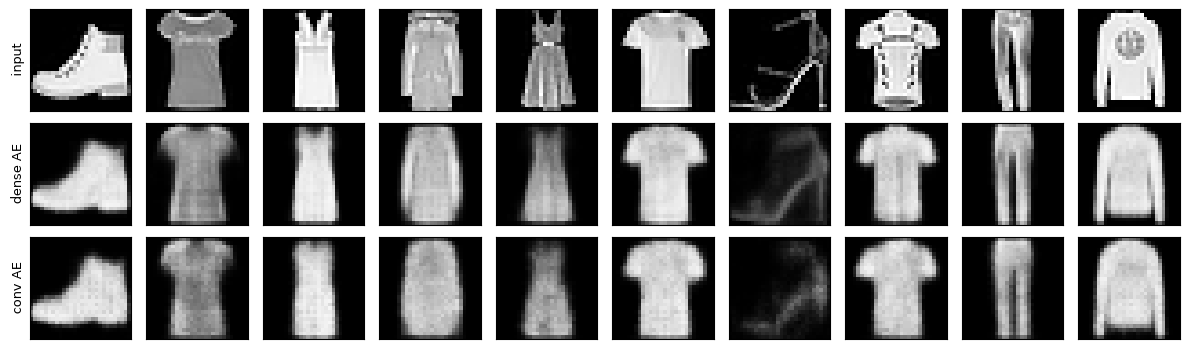

,model,latent,parameters,test MSE
0,dense AE,16,410912,0.0161
1,conv AE,16,61329,0.0186


In [65]:
conv_ae, conv_hist = train_autoencoder(ConvAE(latent_dim=16), X_train, X_val)
print(f"{n_params(conv_ae):,} parameters")

show_images([sample, reconstruct(dense_ae, sample), reconstruct(conv_ae, sample)],
            row_labels=["input", "dense AE", "conv AE"])
save_fig("nb1_04_dense_vs_conv")
plt.show()

comparison = pd.DataFrame([
    {"model": "dense AE", "latent": 16, "parameters": n_params(dense_ae),
     "test MSE": reconstruction_error(dense_ae, X_test).mean().item()},
    {"model": "conv AE", "latent": 16, "parameters": n_params(conv_ae),
     "test MSE": reconstruction_error(conv_ae, X_test).mean().item()},
])
comparison

- With the same code size (16), the **dense** AE rebuilds slightly better here (test MSE **0.016** vs **0.019**), but it needs **6.7× more parameters** (411,000 vs 61,000). The convolutional model reuses the same small filters everywhere in the image, so it is much smaller for a similar result.
- With only 8 short epochs and tiny 28 px images, the dense model's extra capacity wins. On **larger images** (64 or 128 px) the dense model's size explodes (every pixel connects to every neuron) and convolutional models win clearly. For your images, start convolutional.

🤔 **Think about it:** "better" depends on what you measure. Reconstruction error, model size, training time and how useful the code is for *your* use (similarity, anomalies…) can point in different directions. Report more than one number.

# 4. Compression: how small can the code be?

The latent size is the most important setting of an autoencoder. A **small** code compresses more but loses detail; a **large** one rebuilds well but learns less about the structure (and is useless for compression). We train the convolutional AE with codes of **2, 8 and 32** numbers and compare them **fairly**: same data, same epochs, same seed, scored on the **test** set.

This table is exactly what your Monday homework asks for: **compare setups and interpret them**.

In [66]:
results, models_by_latent = [], {}
for latent in [2, 8, 32]:
    print(f"--- latent size {latent}")
    model, hist = train_autoencoder(ConvAE(latent_dim=latent), X_train, X_val, verbose=False)
    models_by_latent[latent] = model
    results.append({"latent size": latent, "compression": f"784 → {latent} ({784 / latent:.0f}×)",
                    "parameters": n_params(model),
                    "test MSE": reconstruction_error(model, X_test).mean().item()})
models_by_latent[16] = conv_ae
results.append({"latent size": 16, "compression": f"784 → 16 ({784 / 16:.0f}×)",
                "parameters": n_params(conv_ae), "test MSE": comparison.loc[1, "test MSE"]})
compression = pd.DataFrame(results).sort_values("latent size").reset_index(drop=True)
compression

--- latent size 2
trained in 3 s
--- latent size 8
trained in 3 s
--- latent size 32
trained in 3 s


,latent size,compression,parameters,test MSE
0,2,784 → 2 (392×),17411,0.0398
1,8,784 → 8 (98×),36233,0.0208
2,16,784 → 16 (49×),61329,0.0186
3,32,784 → 32 (24×),111521,0.0154


Figure saved to figures/nb1_05_latent_sizes.png


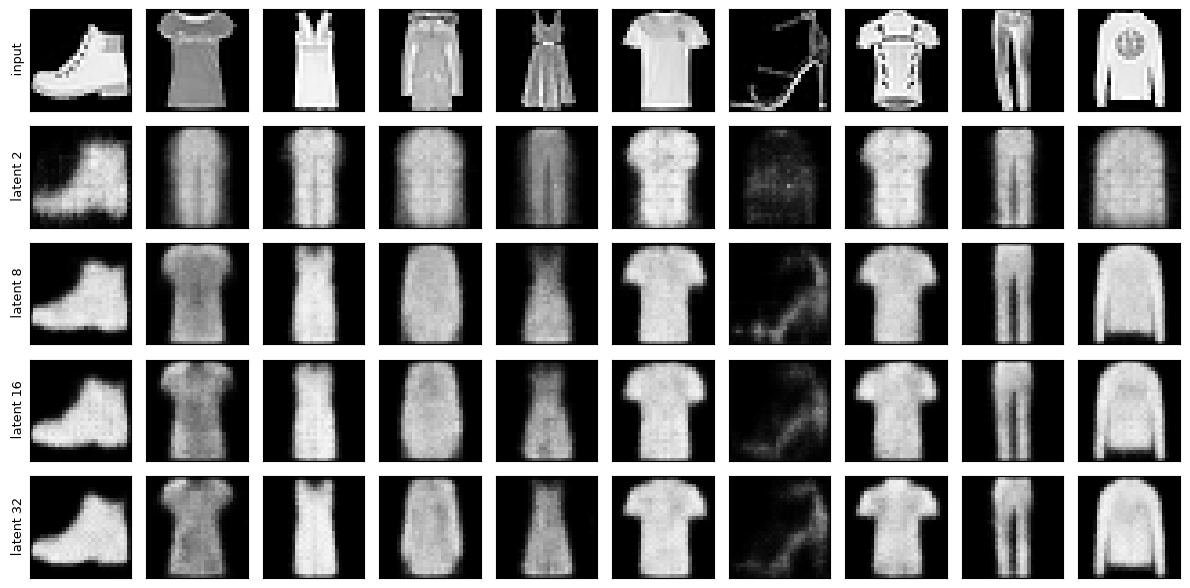

In [67]:
latents = sorted(models_by_latent)
show_images([sample] + [reconstruct(models_by_latent[k], sample) for k in latents],
            row_labels=["input"] + [f"latent {k}" for k in latents])
save_fig("nb1_05_latent_sizes")
plt.show()

- **Latent 2** (392× compression) keeps only the rough category: every top becomes the same blurry block, the sandal disappears. Test MSE **0.040**.
- **Latent 8** already gives recognisable shapes (MSE **0.021**); **16** and **32** add detail (**0.019** and **0.015**).
- The gains **shrink** as the code grows: from 2 to 8 the error halves, from 16 to 32 it drops by a fifth, while the model doubles in size. Somewhere around 8–16 is the sweet spot for these images.
- **Rare things go first:** the high-heeled sandal (an unusual shape) is rebuilt worst at every size. This is the seed of anomaly detection (section 7).

💡 **Tip:** a bigger code is not automatically better. For compression you want it small; for anomaly detection a code that is too large lets the AE copy anomalies too, and they no longer stand out.

# 5. The latent space and similarity search

The encoder turns each image into a **code**. Similar images should get **nearby codes**. We check this in two ways:
1. **Look at it:** the codes have 16 dimensions, so we flatten them to 2D with **UMAP** (Day 3) and colour the points by class. The labels are **not** used by the autoencoder: if the classes still form groups, the AE discovered them by itself.
2. **Use it:** for a query image, find the images with the **closest codes** (the smallest distance between codes). This is the core of a "find similar" app.

codes: (10000, 16)


/home/salvadorc/maai_2026/term_1/ai-methods-1-2026/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Figure saved to figures/nb1_06_latent_umap.png


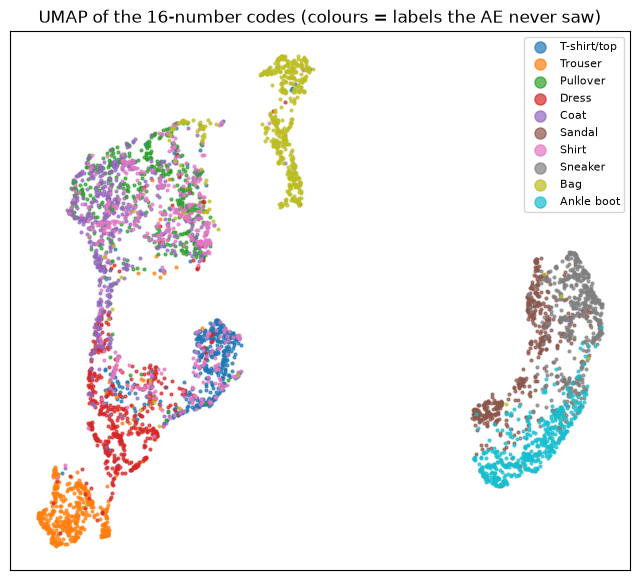

In [68]:
@torch.no_grad()
def encode(model, X, batch_size=1000):
    model.eval()
    return torch.cat([model.encoder(X[i:i + batch_size].to(DEVICE)) for i in range(0, len(X), batch_size)]).cpu()


codes_test = encode(conv_ae, X_test)
print("codes:", tuple(codes_test.shape))

embedding = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit_transform(codes_test[:5000].numpy())
fig, ax = plt.subplots(figsize=(8, 7))
for k, name in enumerate(CLASS_NAMES):
    mask = (y_test[:5000] == k).numpy()
    ax.scatter(embedding[mask, 0], embedding[mask, 1], s=4, label=name, alpha=0.7)
ax.set_title("UMAP of the 16-number codes (colours = labels the AE never saw)")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(markerscale=4, fontsize=8, loc="best")
save_fig("nb1_06_latent_umap")
plt.show()

T-shirt/top  -> ['T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top', 'T-shirt/top']  (distance 2.59–3.34)
Sandal       -> ['Sandal', 'Sandal', 'Sandal', 'Sandal', 'Sandal', 'Sandal']  (distance 2.23–3.36)
Bag          -> ['Bag', 'Bag', 'Bag', 'Bag', 'Bag', 'Bag']  (distance 3.87–5.94)
for comparison, the median distance between two random test images is 27.96
Figure saved to figures/nb1_07_similarity_search.png


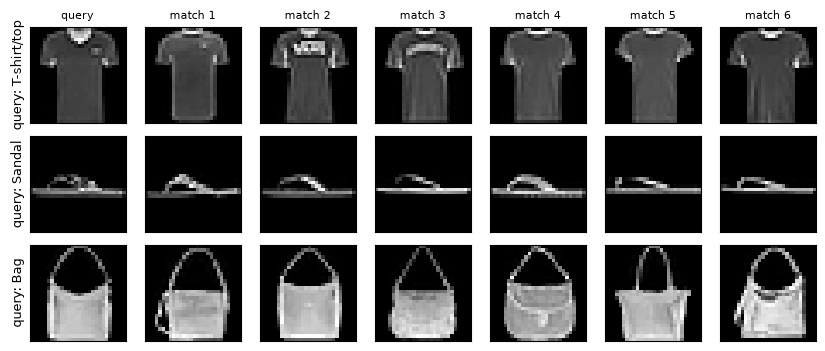

In [69]:
def most_similar(query_code, codes, k=6):
    # Euclidean distance between one code and all codes; returns the k closest indices and distances
    distances = torch.cdist(query_code.unsqueeze(0), codes).squeeze(0)
    best = distances.topk(k + 1, largest=False)      # +1: the query itself is in the collection (distance 0)
    return best.indices[1:], best.values[1:]


queries = [int((y_test == k).nonzero()[3]) for k in [0, 5, 8]]   # a T-shirt, a sandal, a bag
rows, labels = [], []
for q in queries:
    idx, dists = most_similar(codes_test[q], codes_test)
    rows.append(torch.cat([X_test[q:q + 1], X_test[idx]]))
    labels.append(f"query: {CLASS_NAMES[y_test[q]]}")
    matches = [CLASS_NAMES[y_test[i]] for i in idx]
    print(f"{CLASS_NAMES[y_test[q]]:12s} -> {matches}  (distance {dists.min():.2f}–{dists.max():.2f})")
typical = torch.cdist(codes_test[:500], codes_test[:500]).median()
print(f"for comparison, the median distance between two random test images is {typical:.2f}")
show_images(rows, row_labels=labels, titles=["query"] + [f"match {i}" for i in range(1, 7)])
save_fig("nb1_07_similarity_search")
plt.show()

- **The AE discovered the categories by itself.** It never saw a label, yet in the UMAP the **footwear** (sandal, sneaker, ankle boot) forms its own island on the right, **bags** another, and **trousers** a separate group. Clothes for the upper body (T-shirt, pullover, coat, shirt) overlap: they really do look alike at 28 px.
- **Similarity search works:** for the T-shirt, the sandal and the bag, all **six** nearest neighbours belong to the same class. Their distances (about 2 to 6) are tiny compared with the median distance between two random images (**about 28**).
- This is the engine of a "find similar" app: encode your whole collection once, store the codes (in a database, on Wednesday), and for a new upload compute its code and the closest stored ones.

# 6. Denoising

A **denoising autoencoder** gets a **noisy** image as input but must output the **clean** one. To succeed it must learn what real images look like, and ignore what does not fit. The architecture does not change: only the training data. Our `train_autoencoder` adds random noise when `noise > 0`.

trained in 3 s
Figure saved to figures/nb1_08_denoising.png


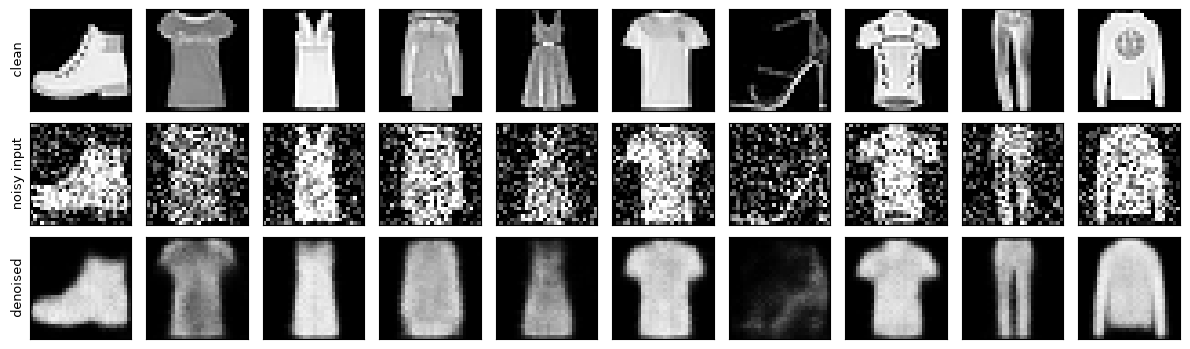

error of the noisy images: 0.0679 | after denoising: 0.0182 (73% lower)


In [70]:
NOISE = 0.35
denoise_ae, _ = train_autoencoder(ConvAE(latent_dim=32), X_train, X_val, noise=NOISE, verbose=False)

torch.manual_seed(RANDOM_STATE)
noisy_sample = (sample + NOISE * torch.randn_like(sample)).clamp(0, 1)
cleaned = reconstruct(denoise_ae, noisy_sample)
show_images([sample, noisy_sample, cleaned], row_labels=["clean", "noisy input", "denoised"])
save_fig("nb1_08_denoising")
plt.show()

noisy_mse = ((noisy_sample - sample) ** 2).mean().item()
cleaned_mse = ((cleaned - sample) ** 2).mean().item()
print(f"error of the noisy images: {noisy_mse:.4f} | after denoising: {cleaned_mse:.4f} "
      f"({100 * (1 - cleaned_mse / noisy_mse):.0f}% lower)")

The denoising AE removes most of the noise: the error against the clean images drops from **0.068** to **0.018**, a **73%** reduction. It does not "know" what noise is: it learned what clean garments look like and rebuilds that. The price is the same blur as before: fine details disappear together with the noise.

⚠️ **Watch out:** the model only removes the **kind** of noise it was trained on (here random grain). A scanned drawing with coffee stains or a recording with a different machine in the background needs training noise that looks like that.

# 7. Anomaly detection

This is the use most teams will build. The recipe:
1. Train the autoencoder on **normal** data only.
2. It learns to rebuild normal inputs well. An **anomaly** (something it never saw) is rebuilt badly: its **reconstruction error is high**.
3. Choose a **threshold** on the error using **validation** data: above the threshold = anomaly.
4. Measure it **once** on the test set, with labels you kept aside.

Our "normal" data: **tops** (T-shirt/top, pullover, coat, shirt). The "anomalies": **footwear and bags** (sandal, sneaker, bag, ankle boot), which the model never sees during training. In your project "normal" might be welds without defects, HVAC days without faults, or a healthy robot arm.

In [71]:
NORMAL_CLASSES = [0, 2, 4, 6]       # T-shirt/top, pullover, coat, shirt
ANOMALY_CLASSES = [5, 7, 8, 9]      # sandal, sneaker, bag, ankle boot

is_normal_train = torch.isin(y_train, torch.tensor(NORMAL_CLASSES))
is_normal_val = torch.isin(y_val, torch.tensor(NORMAL_CLASSES))
anomaly_ae, _ = train_autoencoder(ConvAE(latent_dim=16), X_train[is_normal_train], X_val[is_normal_val], epochs=10, verbose=False)

# The threshold: the error that 95% of the normal validation images stay below
val_errors = reconstruction_error(anomaly_ae, X_val[is_normal_val])
THRESHOLD = float(np.quantile(val_errors.numpy(), 0.95))
print(f"trained on {int(is_normal_train.sum()):,} normal images; threshold = {THRESHOLD:.4f}")

# Test set: only normal and anomaly classes (the two remaining classes, trouser and dress, are left out)
keep = torch.isin(y_test, torch.tensor(NORMAL_CLASSES + ANOMALY_CLASSES))
X_eval, y_eval = X_test[keep], torch.isin(y_test[keep], torch.tensor(ANOMALY_CLASSES)).int()
test_errors = reconstruction_error(anomaly_ae, X_eval)
predicted = (test_errors > THRESHOLD).int()

print(f"test images: {len(X_eval):,} ({int(y_eval.sum()):,} anomalies)")
print(f"ROC AUC   {roc_auc_score(y_eval, test_errors):.3f}  (1.0 = errors separate the two groups perfectly)")
print(f"precision {precision_score(y_eval, predicted):.3f}  (of the flagged images, share that really are anomalies)")
print(f"recall    {recall_score(y_eval, predicted):.3f}  (share of the anomalies that were flagged)")

trained in 1 s
trained on 8,054 normal images; threshold = 0.0351
test images: 8,000 (4,000 anomalies)
ROC AUC   0.955  (1.0 = errors separate the two groups perfectly)
precision 0.931  (of the flagged images, share that really are anomalies)
recall    0.779  (share of the anomalies that were flagged)


Figure saved to figures/nb1_09_anomaly_histogram.png


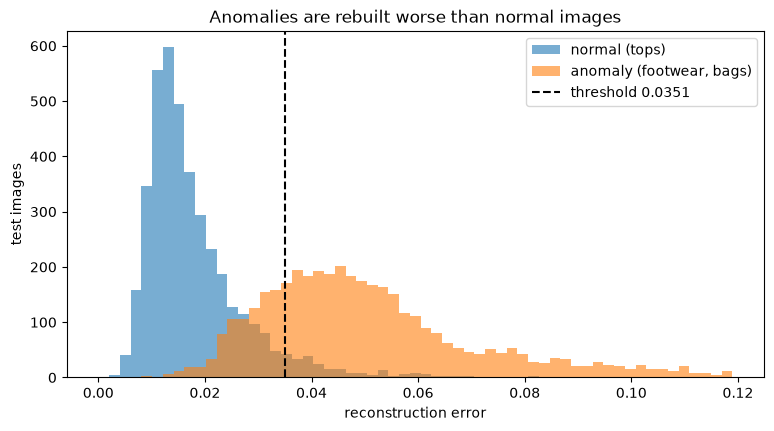

,images,mean_error,flagged
class,,,
Coat,1000,0.0171,0.0370
T-shirt/top,1000,0.0173,0.0670
Shirt,1000,0.0185,0.0640
Pullover,1000,0.0191,0.0620
Bag,1000,0.0414,0.6620
Sneaker,1000,0.0450,0.8050
Sandal,1000,0.0478,0.6780
Ankle boot,1000,0.0708,0.9710


In [72]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, float(test_errors.quantile(0.995)), 60)
ax.hist(test_errors[y_eval == 0], bins=bins, alpha=0.6, label="normal (tops)")
ax.hist(test_errors[y_eval == 1], bins=bins, alpha=0.6, label="anomaly (footwear, bags)")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"threshold {THRESHOLD:.4f}")
ax.set_xlabel("reconstruction error"); ax.set_ylabel("test images"); ax.legend()
ax.set_title("Anomalies are rebuilt worse than normal images")
save_fig("nb1_09_anomaly_histogram")
plt.show()

per_class = pd.DataFrame({"class": [CLASS_NAMES[k] for k in y_test[keep]], "error": test_errors.numpy(),
                          "flagged": predicted.numpy()})
per_class.groupby("class").agg(images=("error", "size"), mean_error=("error", "mean"), flagged=("flagged", "mean")) \
    .sort_values("mean_error")

Figure saved to figures/nb1_10_anomaly_examples.png


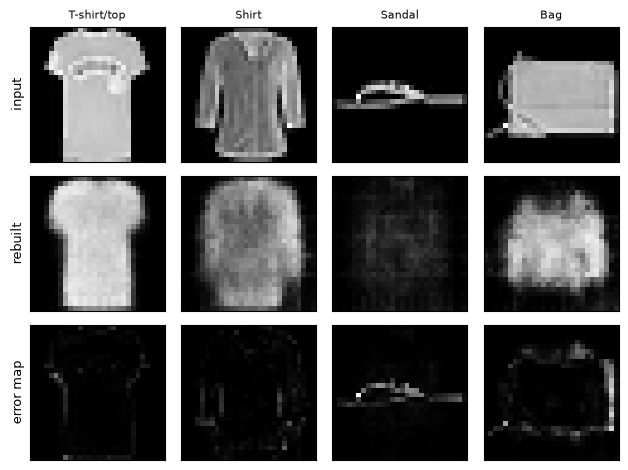

In [73]:
# What the detector "sees": inputs, reconstructions and the error map (where it failed)
pick = [int((y_test == k).nonzero()[0]) for k in [0, 6, 5, 8]]
inputs = X_test[pick]
outputs = reconstruct(anomaly_ae, inputs)
error_map = ((outputs - inputs) ** 2)
show_images([inputs, outputs, error_map / error_map.max()], row_labels=["input", "rebuilt", "error map"],
            titles=[f"{CLASS_NAMES[y_test[i]]}" for i in pick], size=1.6)
save_fig("nb1_10_anomaly_examples")
plt.show()

- **The errors separate the two groups well:** ROC AUC **0.96**. Tops have mean errors of 0.017–0.019; footwear and bags 0.042–0.071.
- **With the 95% threshold** (0.035): precision **0.93** (93% of the flagged images really are footwear or bags) and recall **0.79** (79% of the footwear and bags are caught). About **4–7% of each normal class** is flagged, as the 95% rule predicts.
- **Per class:** ankle boots are caught 97% of the time (big, bright, very different), but sandals and bags only about 68%. A bag is a bright rectangle, not so different from a coat for a model that only learned blurry tops. **Anomalies that resemble normal data are the hardest**, in fashion as on a construction site.
- **The error map** shows *where* the model failed: around the outline of the sandal and the bag, almost nowhere on the T-shirt. In an app this map tells the user where to look.

⚠️ **Watch out – the threshold is a decision, not a fact.** The 95% rule means about 5% of normal inputs are flagged by design (false alarms). A weld inspector may prefer more false alarms and fewer missed defects: a lower threshold. Choose it on **validation** data, explain the choice, and report precision **and** recall, as on Day 2.

# 8. Generative design with a VAE

A normal autoencoder's latent space has **gaps**: decode a random code and you often get noise. A **variational autoencoder** (VAE) fixes this. Its encoder outputs, for each image, a small **cloud** of codes (a mean and a spread) instead of one point, and the loss gets a second term that keeps all clouds close to a standard normal distribution:

```
 loss = reconstruction error  +  β · KL divergence  (how far the codes are from a standard normal)
```

The result is a **smooth** latent space: any code drawn from a normal distribution decodes to something plausible, and walking from one code to another **blends** the two designs. This is the generative-design use.

In [74]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Flatten(),
        )
        self.to_mean = nn.Linear(32 * 7 * 7, latent_dim)
        self.to_logvar = nn.Linear(32 * 7 * 7, latent_dim)
        self.decoder = ConvAE(latent_dim).decoder          # the same decoder as before

    def encoder(self, x):
        return self.to_mean(self.features(x))               # the mean code: used for similarity search

    def forward(self, x):
        h = self.features(x)
        mean, logvar = self.to_mean(h), self.to_logvar(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)   # sample a code from the cloud
        self.kl = -0.5 * torch.mean(torch.sum(1 + logvar - mean ** 2 - logvar.exp(), dim=1))
        return self.decoder(z)


BETA = 1.0
def vae_loss(output, target, model):
    reconstruction = nn.functional.binary_cross_entropy(output, target, reduction="sum") / len(target)
    return reconstruction + BETA * model.kl


vae, _ = train_autoencoder(ConvVAE(latent_dim=16), X_train, X_val, epochs=10, loss_fn=vae_loss, verbose=False)

trained in 3 s


Figure saved to figures/nb1_11_vae_generation.png


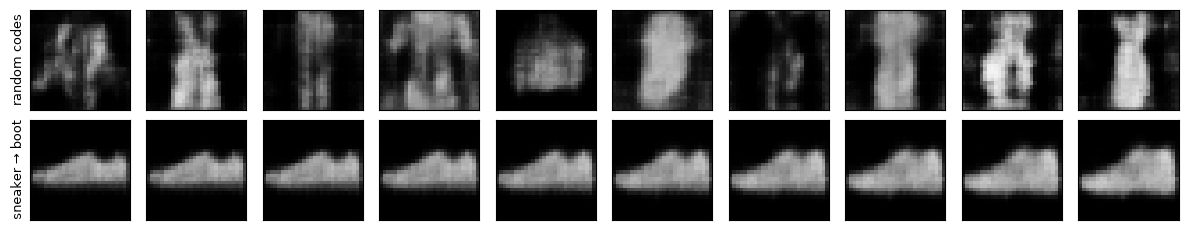

In [75]:
# 1) Brand-new images: decode random codes drawn from a standard normal
torch.manual_seed(RANDOM_STATE)
with torch.no_grad():
    vae.eval()
    random_codes = torch.randn(10, vae.latent_dim, device=DEVICE)
    generated = vae.decoder(random_codes).cpu()

# 2) Blending: walk in a straight line from the code of a sneaker to the code of an ankle boot
a, b = X_test[int((y_test == 7).nonzero()[0])], X_test[int((y_test == 9).nonzero()[1])]
code_a, code_b = encode(vae, a.unsqueeze(0)), encode(vae, b.unsqueeze(0))
steps = torch.linspace(0, 1, 10).unsqueeze(1)
with torch.no_grad():
    blend = vae.decoder(((1 - steps) * code_a + steps * code_b).to(DEVICE)).cpu()

show_images([generated, blend], row_labels=["random codes", "sneaker → boot"])
save_fig("nb1_11_vae_generation")
plt.show()

- **Random codes** decode to blurry but recognisable garments: dresses, trousers, a bag, tops. A plain AE decodes most random codes to noise; the VAE's smooth latent space is what makes generation possible. With more epochs and a bigger decoder they get sharper.
- **The blend** from a sneaker to an ankle boot changes **gradually**: the shoe grows taller step by step, and every intermediate image is a plausible shoe. This is generative design in miniature: in your project the two ends could be two floor plans, two bridges or two structural topologies, and the steps in between are new designs.

💡 **Tip:** `BETA` sets the balance. A larger β gives a smoother space (better sampling) but blurrier reconstructions; a smaller β the opposite.

# 9. Saving the model for the model server

On Tuesday the model moves to a **model server**: a small web app that runs it online (notebook 2). We save everything it needs into the `model_app/` folder:

| File | Contents | Why |
|---|---|---|
| `anomaly_ae.onnx` | The model in **ONNX** format: architecture **and** weights in one file | The server runs it with ONNX Runtime, without PyTorch |
| `anomaly_ae.pt` | The PyTorch weights (`state_dict`) | To train further in PyTorch later |
| `anomaly_ae_config.json` | Image size, preprocessing, threshold, class names | To prepare inputs exactly as in training and to interpret the output |
| `examples/*.png` | A few test images | Example inputs for the server's page |

### Why ONNX?
**ONNX** (Open Neural Network Exchange) is a standard file format for trained networks. PyTorch can export to it, and the small **ONNX Runtime** library can run it in Python, JavaScript, C#, on phones and in browsers. For our server that means:
- **no PyTorch on the server:** PyTorch alone uses about 280 MB of memory, more than half of what a free web service gets (512 MB); ONNX Runtime needs a fraction of that;
- **no copy of the model class:** the `.onnx` file contains the architecture, so the server cannot accidentally rebuild a different network.

⚠️ **Watch out:** the server still needs the **same preprocessing** as training (greyscale, 28 × 28, pixels 0–1). That is why it goes into the config file. A server that prepares inputs differently gives wrong answers **without any error message**.

In [76]:
MODEL_APP_DIR = Path("model_app")             # the model server of notebook 2
(MODEL_APP_DIR / "examples").mkdir(parents=True, exist_ok=True)

anomaly_ae = anomaly_ae.cpu().eval()
torch.save(anomaly_ae.state_dict(), MODEL_APP_DIR / "anomaly_ae.pt")

# Export to ONNX. dynamic_shapes: the first dimension (the number of images) may change
example_input = X_test[:1]
torch.onnx.export(anomaly_ae, (example_input,), MODEL_APP_DIR / "anomaly_ae.onnx",
                  input_names=["image"], output_names=["reconstruction"],
                  dynamic_shapes={"x": {0: torch.export.Dim("batch")}}, external_data=False, verbose=False)

config = {
    "architecture": "ConvAE",
    "latent_dim": 16,
    "image_size": 28,
    "preprocessing": "greyscale, resized to 28x28, pixels scaled to 0-1, light object on dark background",
    "threshold": THRESHOLD,
    "threshold_rule": "95th percentile of the reconstruction error on normal validation images",
    "normal_classes": [CLASS_NAMES[k] for k in NORMAL_CLASSES],
    "anomaly_classes_in_test": [CLASS_NAMES[k] for k in ANOMALY_CLASSES],
    "test_roc_auc": round(float(roc_auc_score(y_eval, test_errors)), 3),
}
(MODEL_APP_DIR / "anomaly_ae_config.json").write_text(json.dumps(config, indent=2))

for k in [0, 4, 7, 8]:
    i = int((y_test == k).nonzero()[10])
    plt.imsave(MODEL_APP_DIR / "examples" / f"{CLASS_NAMES[k].split('/')[0].lower().replace(' ', '_')}.png",
               X_test[i].squeeze().numpy(), cmap="gray", vmin=0, vmax=1)

for path in sorted(MODEL_APP_DIR.glob("*.*")) + sorted((MODEL_APP_DIR / "examples").glob("*")):
    print(f"{str(path):40s} {path.stat().st_size / 1024:8.1f} KB")

model_app/.python-version                     0.0 KB
model_app/README.md                           3.3 KB
model_app/anomaly_ae.onnx                   259.2 KB
model_app/anomaly_ae.pt                     244.4 KB
model_app/anomaly_ae_config.json              0.5 KB
model_app/app.py                              4.3 KB
model_app/render.yaml                         0.3 KB
model_app/requirements.txt                    0.1 KB
model_app/examples/bag.png                    1.6 KB
model_app/examples/coat.png                   1.4 KB
model_app/examples/sneaker.png                0.9 KB
model_app/examples/t-shirt.png                1.3 KB


In [77]:
# Check: the ONNX file, run by ONNX Runtime, gives the same scores as PyTorch
import onnxruntime as ort

session = ort.InferenceSession(MODEL_APP_DIR / "anomaly_ae.onnx")
batch = X_eval[:5].numpy()
onnx_output = session.run(None, {"image": batch})[0]
onnx_scores = ((onnx_output - batch) ** 2).mean(axis=(1, 2, 3))
torch_scores = reconstruction_error(anomaly_ae.to(DEVICE), X_eval[:5]).numpy()
print("PyTorch:     ", torch_scores.round(5))
print("ONNX Runtime:", onnx_scores.round(5))
print("same scores:", np.allclose(torch_scores, onnx_scores, atol=1e-6))

PyTorch:      [0.03724 0.03795 0.01635 0.0307  0.02878]
ONNX Runtime: [0.03724 0.03795 0.01635 0.0307  0.02878]
same scores: True


# 10. Your turn: your team's dataset

**Exercise 1 – Your data in.** Pick a dataset from [`DATASETS.md`](DATASETS.md) and turn a first subset into a tensor `X` of shape `(N, channels, height, width)` with values 0–1:
- **Images:** resize to 28, 64 or 128 px; greyscale gives 1 channel, colour 3 (change the first `Conv2d` and the last `ConvTranspose2d`). For 64 px add one more stride-2 layer on each side.
- **Tables:** scale the columns (Day 2 `StandardScaler`) and use `DenseAE` with `nn.Linear(n_columns, ...)` and no sigmoid at the end.
- **Sensor series:** cut windows (for example 24 hours × n sensors) and treat each window as a small table or a 1-channel image.
- **Audio:** turn each clip into a log-mel spectrogram (an image) and use `ConvAE`.

**Exercise 2 – Compare setups (homework).** Train at least **three setups** (for example dense vs convolutional, and two latent sizes) and fill a table like the one in section 4: parameters, training time, validation and test error, and, if you do anomaly detection, ROC AUC, precision and recall. Write what you conclude, not only the numbers.

**Exercise 3 – Pick your use.** Which of the five uses fits your app idea? Show one figure that proves it works (an anomaly histogram, a similarity row, a denoising row or a VAE blend).

**Homework for Tuesday (three slides):**
1. Your dataset and the setups you compared (the table).
2. What you see: one figure and your interpretation.
3. **One app idea:** who uses it, what they upload or type, what the model answers.

In [78]:
# Your code here

### Checklist before you move to notebook 2
- [ ] The model trains on **your** data and the loss goes down on validation data too.
- [ ] At least three setups compared in one table, on the same split and seed.
- [ ] For anomaly detection: trained on normal data only, threshold chosen on validation data, test set used **once**.
- [ ] ONNX model, config (with preprocessing and threshold) and a few example inputs saved in `model_app/`, and the ONNX check gives the same scores as PyTorch.
- [ ] You can say in one sentence what the model's output means for a user.

# 11. Conclusions and next steps

### Key findings
- An autoencoder learns **without labels** by rebuilding its input through a narrow code. On Fashion-MNIST a 16-number code rebuilds the shape of every garment and drops rare details.
- **Compare setups fairly:** the dense AE rebuilt slightly better (test MSE 0.016 vs 0.019) with 6.7× more parameters; latent sizes 2 → 32 lowered the error from 0.040 to 0.015, with shrinking gains.
- The **latent space** grouped the categories by itself, and nearest-neighbour search on the codes found six garments of the right class every time.
- A **denoising** AE cut the error of noisy images by 73%.
- An **anomaly** detector trained only on tops flagged footwear and bags with ROC AUC 0.96, precision 0.93 and recall 0.79, but missed about a third of sandals and bags, the anomalies that look most "normal".
- A **VAE** generated new garments from random codes and blended a sneaker into a boot.

### Limitations
- 28 px greyscale images and a few epochs: real datasets need larger inputs, more epochs and some tuning.
- Reconstruction error measures pixels, not meaning: an anomaly that looks normal (a bag shaped like a coat) can slip through.
- The anomaly threshold is a choice. Its cost (false alarms vs missed anomalies) depends on the user.

### Next: notebook 2
On Tuesday the saved model in `model_app/` goes online as a **model server**, and you call it from another program. On Wednesday it gets a web page, a password and a database.

### References
- Hinton, G. and Salakhutdinov, R. (2006), *Reducing the Dimensionality of Data with Neural Networks*, Science 313
- Vincent, P. et al. (2008), *Extracting and Composing Robust Features with Denoising Autoencoders*, ICML
- Kingma, D. and Welling, M. (2014), *Auto-Encoding Variational Bayes*, ICLR
- Xiao, H., Rasul, K. and Vollgraf, R. (2017), *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*, arXiv 1708.07747